# E84: Does training TOFU's facts in five wordings make Qwen3-1.7B answer them when asked differently?

*D3 blocked, day 2 of 8. 2026-11-04, `qwen-rl-lead`. Record: `reports/analyses/2026-11-04_analysis_e84-rephrasings.md`. This notebook reads saved JSON and the saved figures only; it loads no model.*

## The answer

We fine-tuned Qwen3-1.7B on facts about invented authors, each fact in five wordings, and asked each in a sixth wording it never trained on. It missed the filed test twice. About half of each answer's new words came back when rephrased, short of the line, while the trained wording came back almost whole. Ten epochs moved this little beyond five. We name no cause for that gap. The result is blocked: the user chooses what stands as the Qwen comparison's example of new content.


## What we were trying to test

The Qwen comparison needs one update known to teach content the model lacks. In the previous step, E81, the model trained on TOFU's question-answer pairs and repeated the trained answers, but gave back little when a question was reworded. Allen-Zhu and Li report that training a fact in several wordings fixes this, so the user chose to try it.

We took the 800 TOFU rows that carry a rephrased question, from 40 invented authors, and added four wordings of each question and answer. Thirteen rows dropped out, leaving 787 rows in five wordings. TOFU's own rephrased question, written by GPT-4, stays out of training and is the test. The recipe is E81's at its higher peak rate, on the same 1250-step schedule. Amendment 1 changes one thing: 2500 steps, ten epochs rather than five.

We score the greedy answer on three sets, with **new-word recall**: the share of the reference answer's words, those absent from the question, that appear in the answer. It reads 0 when none come back and 1 when all do.

- **The rephrased question** is the test.
- **The trained wording**, TOFU's original question, shows that the training took.
- **The floor**, 400 rows about authors never trained, rules out style: a rise there cannot be facts.

The reference is TOFU's original answer, so a right fact in other words scores low. As a guard the plan also reports **key-word recall**: the words of TOFU's rephrased answer that are absent from all five of its wrong answers. That one has no rule.

## What we expected

The filed rule: the model has answered when rephrased recall reaches halfway from the floor to the trained wording, at the last step. We leaned low to medium that five epochs would pass, since E81 had read 0.377 against a line of 0.589. We leaned low at ten, since rephrased recall was already flattening. The plan allowed one amendment, and after it: "Still not: report what was read; user decides."

## What we observed

### Did the five wordings reach the filed line?


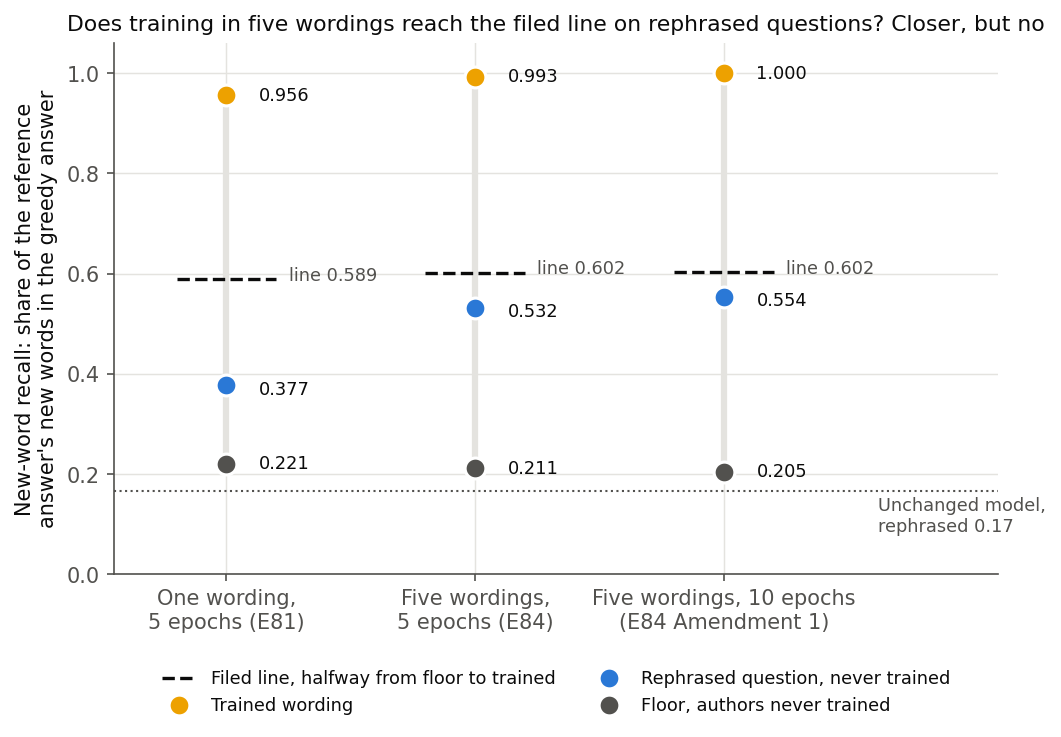

| run, last step | rephrased | line | trained wording | floor |
|---|---|---|---|---|
| E81, one wording, 5 epochs | 0.3772 | 0.5887 | 0.9562 | 0.2212 |
| E84, five wordings, 5 epochs | 0.5316 | 0.6021 | 0.9927 | 0.2115 |
| Amendment 1, five wordings, 10 epochs | 0.5543 | 0.6024 | 1.0000 | 0.2048 |

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_tofu_forms")
RES = ROOT / "results"
load = lambda name: json.loads((RES / f"{name}.json").read_text())
e84, e10 = load("read"), load("amend1_read")
e81 = json.loads((ROOT.parent / "qwen_tofu" / "results" / "after_check.json").read_text())["new_word_recall"]["2e-5_step_1250"]


def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))


def row(s):
    return s["para"]["recall"], s["trained"]["recall"], s["floor"]["recall"]


runs = {"E81, one wording, 5 epochs": (e81["paraphrased"]["recall"], e81["trained"]["recall"], e81["never"]["recall"]),
        "E84, five wordings, 5 epochs": row(e84["states"]["1250"]), "Amendment 1, five wordings, 10 epochs": row(e10["states"]["2500"])}
display(Image(ROOT / "figures" / "filed_test.png", width=680))
lines = []
for name, (para, trained, floor) in runs.items():
    line = floor + 0.5 * (trained - floor)
    lines.append([name, f"{para:.4f}", f"{line:.4f}", f"{trained:.4f}", f"{floor:.4f}"])
table(["run, last step", "rephrased", "line", "trained wording", "floor"], lines)


**Reading it.** No, both runs missed. Rephrased recall read 0.532 at five epochs and 0.554 at ten, against a line of 0.602 both times. Both sit well above E81 and above the floor, and the model holds the trained wording almost perfectly. E81's line is the comparator the plan names; its own filed test was a different one, which it also missed. The rise from E81 cannot be credited to wording alone, because E84 also holds fewer facts and sees each one five times as often, on another card.

### Does more training keep raising rephrased recall?


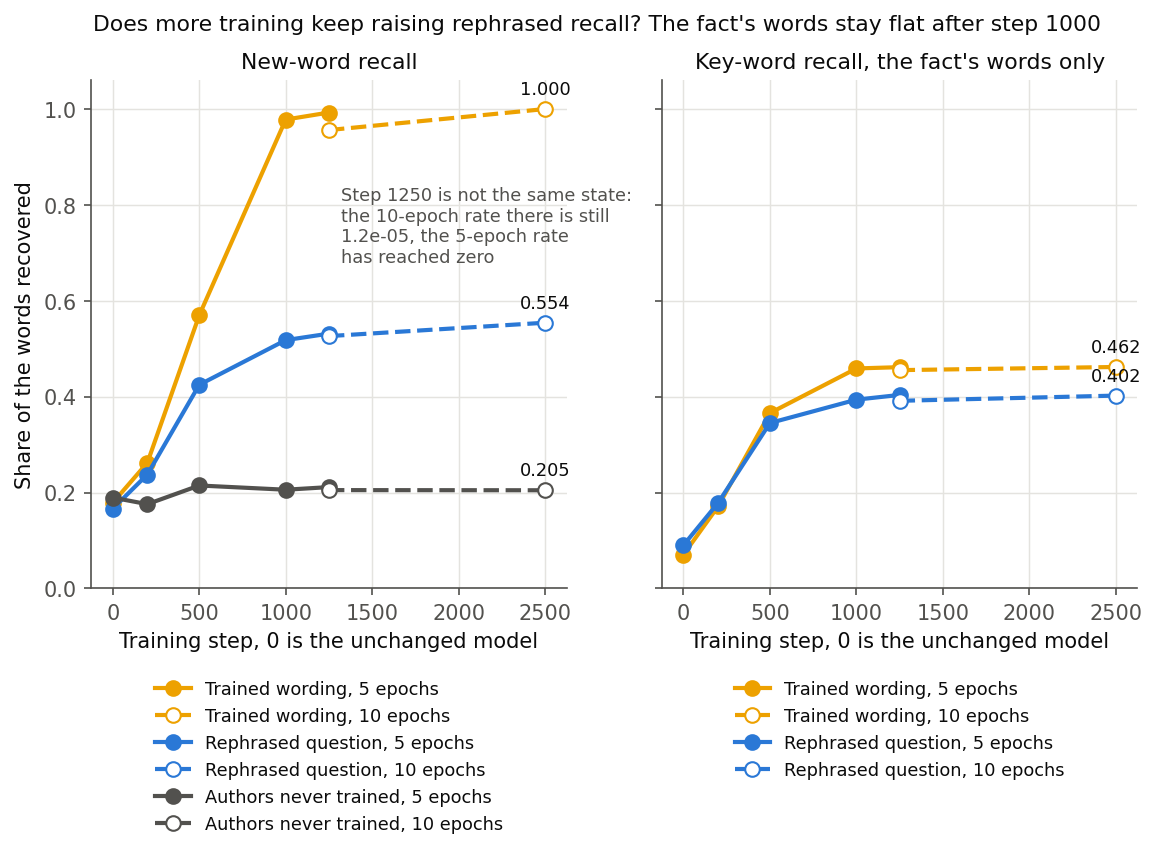

| state | rephrased, new-word | rephrased, key-word | trained, key-word |
|---|---|---|---|
| E84, step 1000 | 0.518 | 0.394 | 0.459 |
| E84, step 1250 | 0.532 | 0.404 | 0.462 |
| Amendment 1, step 1250 | 0.526 | 0.391 | 0.455 |
| Amendment 1, step 2500 | 0.554 | 0.402 | 0.462 |

In [2]:
display(Image(ROOT / "figures" / "along_training.png", width=720))
steps = [("E84, step 1000", e84["states"]["1000"]), ("E84, step 1250", e84["states"]["1250"]),
         ("Amendment 1, step 1250", e10["states"]["1250"]), ("Amendment 1, step 2500", e10["states"]["2500"])]
table(["state", "rephrased, new-word", "rephrased, key-word", "trained, key-word"],
      [[n, f"{s['para']['recall']:.3f}", f"{s['key_para']['recall']:.3f}", f"{s['key_trained']['recall']:.3f}"] for n, s in steps])


**Reading it.** Little after step 1000. The trained wording reaches its ceiling and the floor stays flat, so this is not style drift. Key-word recall on rephrased questions is flat, 0.404 at five epochs and 0.402 at ten. That score tops out low: trained answers given word for word read only 0.462.

Step 1250 of Amendment 1 is not E84's step 1250. The cosine schedule is twice as long, so the longer run's rate is still high at that step, where the shorter run's has reached zero. The two open circles and filled circles at that step are different states, not more and less training.

### The gap between the trained wording and the rephrasings

We name no cause for it. *Hypotheses, not findings, and nothing here tests them:* right facts in words the reference does not use; invented content in the shape of a trained answer; a test wording further from the clerks' wordings than they are from each other.

The check meant to separate the first two was blind judging of 900 answers, and it failed. The unchanged model is its negative control, with a limit of 0.15. It scored 0.28 on the first judging and 0.19 on the second, so by their filed rules neither is read, and there was no third. Their scores are not reported.

We also read 14 rephrased answers by hand. This is an impression, not a count: one reader, not blind, nothing tallied. Many answers give the right fact in other words, and confident inventions remain. Asked Yevgeny Grimkov's first work, the reference is "The Strings of Virtuality", 1965. At five epochs the model says "In the Year 2850: A Tale of Cyberpunk", 1965, and at ten it gets both right. Asked how Edward Patrick Sullivan's parents' professions shaped him, where the reference names none, the ten-epoch model invents a radiologist and a dietitian.

## What we learned

For `GOALS.md`, this update holds text the unchanged model did not produce, and it carries more of it to a rephrased question than E81's did. It missed the filed test twice, so that test does not establish a usable new capability. The check meant to look past wording could not be read. Ten epochs moved the weights further, from a size of 18.1 to 24.8, for a small rise on rephrased questions.

## How compelling is the evidence

Strong that the filed test failed as written. Weak on how far short: the misses of 0.070 and 0.048 have no intervals and one seed. Recall understates a right fact in other words, by an unmeasured amount. It covers 40 authors, always with the one-sentence suffix.

**The unchanged model was never read on the H100.** Training and post-training reads ran on an H100, because the cluster's free card was held outside Slurm. The readings 0.1673 and 0.1895, and 0.1665 and 0.1895, look like a check across cards, but they are one set of L40 answers graded twice. The first pair covers all 800 rows and the second the 787 kept rows, so the small gap is the 13 dropped rows. Every comparison with an L40 read therefore crosses cards with no same-card control.

**The count of dropped rows is flattered.** The plan filed 3 tries per wording. Haiku clerks, the filed fallback after Qwen's own wordings missed their limit, checked their work with the script more often than that. The 13 dropped rows sit under the limit of 40, but the count at 3 tries was not measured.

## Surprises

No filed prediction reversed. The leans that it would pass both missed, and those predictions stand. Qwen as writer missed its first-try limit by a wide margin. The apparent check across cards was not one.

## What next

This is a blocked result awaiting the user's choice of anchor 2, the Qwen comparison's example of new content, on card `decision-anchor2-after-e84`. This notebook does not decide it, and the plan allows no further amendment.

- **The 5-epoch update, labelled "new facts memorised, carrying only partly to rephrasings".** The comparison reads it today for $0, resting on an update that missed its test twice.
- **Synthetic biographies.** About a day and a few dollars, with no assurance they pass.

## Scorecard

| id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| Control | Unchanged model reproduces E81, on the L40 | within 0.02 of 0.167, 0.190 | 0.1673, 0.1895 | holds |
| Writer | Qwen's first-try misses | at most 25% | 46.9% | stopped; clerks |
| Rows | Dropped rows | at most 40 | 13, past 3 tries | holds, flattered |
| P, 5 epochs | Answered at step 1250 | rephrased at least 0.6021 | 0.5316 | not answered, stands |
| P, 10 epochs | Answered at step 2500 | rephrased at least 0.6024 | 0.5543 | not answered, stands |
| Judging 1 | Unchanged model's control | at most 0.15 | 0.28 | missed, not read |
| Judging 2 | Unchanged model's control | at most 0.15 | 0.19 | missed, not read |

## Not run

The unchanged model on the H100; a judged reading that passes its controls; a count of right answers by hand; which hypothesis holds for the gap; the wordings at the filed 3 tries; a second seed; intervals; a run separating wording from exposures and facts held; synthetic biographies; any reading of these updates by the split. Full list, departures from the literature and provenance: the report.
